<a href="https://colab.research.google.com/github/Latifmmhd/V2-Retrain-Emotion-with-PEFT/blob/main/V2_ft_with_peft_augmented_bnf16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!unzip fine_tuning.zip

Archive:  fine_tuning.zip
   creating: fine_tuning/
  inflating: fine_tuning/bert_fine_tuning_peft.py  
   creating: fine_tuning/best_params/
   creating: fine_tuning/best_params/.ipynb_checkpoints/
  inflating: fine_tuning/best_params/.ipynb_checkpoints/get_best_params-checkpoint.ipynb  
  inflating: fine_tuning/best_params/best_params.xlsx  
  inflating: fine_tuning/best_params/get_best_params_augmented_bnf16.ipynb  
  inflating: fine_tuning/best_params/p-indobertweet.json  
  inflating: fine_tuning/best_params/p-mbert.json  
  inflating: fine_tuning/best_params/p-xlm-r-base.json  
  inflating: fine_tuning/best_params/p-xlm-r-large.json  
   creating: fine_tuning/best_params/runs/
   creating: fine_tuning/best_params/runs/Jul11_08-57-06_5b463299fe49/
  inflating: fine_tuning/best_params/runs/Jul11_08-57-06_5b463299fe49/events.out.tfevents.1783760229.5b463299fe49.4574.0  
   creating: fine_tuning/best_params/runs/Jul11_09-05-22_5b463299fe49/
  inflating: fine_tuning/best_params/runs/J

In [2]:
%cd fine_tuning

/content/fine_tuning


In [3]:
!pip install -r requirements.txt

  Cloning https://github.com/huggingface/peft (to revision cf04d0353f0343cbf66627228c4495f51669af34) to /tmp/pip-install-hejlorc4/peft_994b01d33ae7479f931f6dc4cd13c825
  Running command git clone --filter=blob:none --quiet https://github.com/huggingface/peft /tmp/pip-install-hejlorc4/peft_994b01d33ae7479f931f6dc4cd13c825
  Running command git rev-parse -q --verify 'sha^cf04d0353f0343cbf66627228c4495f51669af34'
  Running command git fetch -q https://github.com/huggingface/peft cf04d0353f0343cbf66627228c4495f51669af34
  Running command git checkout -q cf04d0353f0343cbf66627228c4495f51669af34
  Resolved https://github.com/huggingface/peft to commit cf04d0353f0343cbf66627228c4495f51669af34
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.5

In [4]:
import pandas as pd
import numpy as np
import os
import torch
import time
import json

from peft import LoraConfig, LoraModel, get_peft_model, TaskType
from datasets import Dataset
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
)

os.environ["TOKENIZERS_PARALLELISM"] = "false"
use_cuda = torch.cuda.is_available()

In [5]:
df = pd.read_csv('dataset/all_data.csv')
train_data = pd.read_csv('dataset/train_augmented.csv')
train_data['label'] = train_data['label'].str.capitalize()
val_data = pd.read_csv('dataset/val.csv')
test_data = pd.read_csv('dataset/test.csv')

# Length train, val, and test
print("Train: ",len(train_data))
print("Val: ",len(val_data))
print("Test: ",len(test_data))

Train:  8472
Val:  1062
Test:  1062


In [6]:
tags = np.unique(df['label'])
num_labels = len(tags)
max_length = 128
label2id = {t: i for i, t in enumerate(tags)}
id2label = {i: t for i, t in enumerate(tags)}

In [7]:
def model_init(model_name):
    global tokenizer
    global data_collator
    global tr_model

    base_model = AutoModelForSequenceClassification.from_pretrained(
        model_name,
        num_labels=num_labels,
        id2label=id2label,
        label2id=label2id
    )
    tokenizer = AutoTokenizer.from_pretrained(model_name, model_max_length=128)

    # Configure LoRA
    lora_config = LoraConfig(
        task_type=TaskType.SEQ_CLS,
        r=8, # Rank of the low-rank matrices
        lora_alpha=32,
        lora_dropout=0.1
    )

    # Wrap the base model with the LoRA configuration
    model = get_peft_model(base_model, lora_config)
    model.print_trainable_parameters()

    return model, tokenizer


def tokenize_function(examples):
    # process the input sequence
    tokenized_input = tokenizer(examples["tweet"],
                                truncation=True,
                                padding='max_length',
                                max_length=max_length)
    # process the labels
    tokenized_input['label'] = [label2id[lb] for lb in examples['label']]

    return tokenized_input


def preprocessing():
    X_train = Dataset.from_pandas(train_data)
    X_val = Dataset.from_pandas(val_data)
    X_test = Dataset.from_pandas(test_data)

    tokenized_train_data = X_train.map(tokenize_function, batched=True)
    tokenized_val_data = X_val.map(tokenize_function, batched=True)
    tokenized_test_data = X_test.map(tokenize_function, batched=True)

    return tokenized_train_data, tokenized_val_data, tokenized_test_data


def compute_metrics(p):
    pred, labels = p
    pred = np.argmax(pred, axis=1)

    true_labels = [tags[l] for l in labels]
    true_predictions = [tags[pr] for pr in pred]

    report = classification_report(true_labels, true_predictions, digits=4)
    acc = accuracy_score(y_true=true_labels, y_pred=true_predictions)
    rec = recall_score(y_true=true_labels, y_pred=true_predictions, average="macro")
    prec = precision_score(y_true=true_labels, y_pred=true_predictions, average="macro")
    f1 = f1_score(y_true=true_labels, y_pred=true_predictions, average="macro", zero_division=1.0)

    print("Classification Report:\n{}".format(report))
    return {"accuracy": acc, "precision": prec, "recall": rec, "f1": f1}

In [8]:
# to generate the confusion matrix

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

def generate_confusion_matrix(true_labels, pred_labels, num_labels):
    cm = confusion_matrix(true_labels, pred_labels)
    labels = [id2label[i] for i in range(num_labels)]
    plt.figure(figsize=(8, 6))
    sns.set(font_scale=1.5)
    sns.heatmap(cm,
                annot=True,
                fmt="d",
                cmap="Blues",
                xticklabels=labels,
                yticklabels=labels)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.yticks(rotation=0)
    plt.show()

In [9]:
def train_model(model_name, output_dir, learning_rate, train_batch_size, eval_batch_size, num_epochs, weight_decay):

    model, tokenizer = model_init(model_name)
    train_tokenized, val_tokenized, test_tokenized = preprocessing()

    training_args = TrainingArguments(
        output_dir=output_dir,
        logging_strategy="epoch",
        eval_strategy="epoch",
        save_strategy="epoch",
        save_total_limit = 1,
        learning_rate=learning_rate,
        num_train_epochs=num_epochs,
        per_device_train_batch_size=train_batch_size,
        per_device_eval_batch_size=eval_batch_size,
        weight_decay=weight_decay,
        load_best_model_at_end=True,
        #push_to_hub=True, # to push to hub during the training
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_tokenized,
        eval_dataset=val_tokenized,
        processing_class=tokenizer,
        compute_metrics=compute_metrics,
    )

    trainer.train()
    trainer.save_model(output_dir)
    #trainer.push_to_hub(commit_message="Training complete")

    # Get the evaluation results
    trainer.eval_dataset=test_tokenized
    evaluation_results = trainer.evaluate()
    print(evaluation_results)

    # make prediction on the test set
    predictions = trainer.predict(test_tokenized)
    pred_labels = np.argmax(predictions.predictions, axis=1)
    true_labels = test_tokenized["label"]

    # Generate confusion matrix
    generate_confusion_matrix(true_labels, pred_labels, num_labels)

    return trainer

In [10]:

def show_log_history(trainer):
    log_history = pd.DataFrame(trainer.state.log_history)
    log_history = log_history.fillna(0)
    log_history = log_history.groupby(["epoch"]).sum()

    log_history[["loss", "eval_loss"]].plot()
    plt.show()

In [11]:
def main(model_name, output_dir, best_params):
    start = time.time()
     # load json file containing best params
    best_params = best_params

    with open(best_params, 'r') as js:
        data = json.load(js)

    print(data)

    # define best params
    num_train_epochs = data['num_train_epochs']
    learning_rate = data['learning_rate']
    train_batch_size = data['per_device_train_batch_size']
    eval_batch_size = data['per_device_eval_batch_size']
    weight_decay = data['weight_decay']

    # training
    tr_model = train_model(model_name=model_name,
                           output_dir=output_dir,
                           learning_rate=learning_rate,
                           train_batch_size=train_batch_size,
                           eval_batch_size=eval_batch_size,
                           num_epochs=num_train_epochs,
                           weight_decay=weight_decay)

    print('Training finished!')

    show_log_history(tr_model)


    end = time.time()
    exec_time = (end - start) / 60
    print(f'Total time: {exec_time} minutes')

{'num_train_epochs': 9, 'learning_rate': 0.0003, 'per_device_train_batch_size': 8, 'per_device_eval_batch_size': 64, 'weight_decay': 0.020836462400267465}


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indolem/indobertweet-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


trainable params: 299,526 || all params: 110,862,348 || trainable%: 0.27017829353569167


Map:   0%|          | 0/8472 [00:00<?, ? examples/s]

Map:   0%|          | 0/1062 [00:00<?, ? examples/s]

...

wandb: Paste your API key and hit enter: ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: 21523190 (21523190-universitas-islam-indonesia) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.946200,0.782475,0.741055,0.740195,0.786362,0.749221
2,0.698800,0.704928,0.742938,0.743984,0.772786,0.751680
3,0.617900,0.700821,0.758004,0.758620,0.778004,0.766076
4,0.542600,0.754071,0.755179,0.754717,0.778861,0.763788
5,0.470600,0.810939,0.749529,0.747445,0.773475,0.757448
6,0.426800,0.890688,0.747646,0.745151,0.773361,0.755520
7,0.377800,0.960521,0.734463,0.733035,0.758566,0.741750
8,0.339000,1.029054,0.736347,0.733931,0.764613,0.743924
9,0.315700,1.016756,0.744821,0.743461,0.767038,0.752340


Classification Report:
              precision    recall  f1-score   support

       Anger     0.7264    0.8750    0.7938       176
        Fear     0.7584    0.9184    0.8308       147
         Joy     0.7558    0.7345    0.7450       177
        Love     0.6516    0.8783    0.7481       115
     Neutral     0.8363    0.4799    0.6098       298
         Sad     0.7126    0.8322    0.7678       149

    accuracy                         0.7411      1062
   macro avg     0.7402    0.7864    0.7492      1062
weighted avg     0.7565    0.7411    0.7306      1062

Classification Report:
              precision    recall  f1-score   support

       Anger     0.7051    0.8693    0.7786       176
        Fear     0.7975    0.8571    0.8262       147
         Joy     0.8121    0.6836    0.7423       177
        Love     0.6781    0.8609    0.7586       115
     Neutral     0.7621    0.5805    0.6590       298
         Sad     0.7091    0.7852    0.7452       149

    accuracy                   

Classification Report:
              precision    recall  f1-score   support

       Anger     0.7756    0.8833    0.8260       180
        Fear     0.8079    0.9104    0.8561       134
         Joy     0.8073    0.8462    0.8263       208
        Love     0.7477    0.7921    0.7692       101
     Neutral     0.8165    0.6117    0.6994       291
         Sad     0.7301    0.8041    0.7653       148

    accuracy                         0.7853      1062
   macro avg     0.7809    0.8080    0.7904      1062
weighted avg     0.7881    0.7853    0.7813      1062

{'eval_loss': 0.6477866768836975, 'eval_accuracy': 0.7853107344632768, 'eval_precision': 0.7808558146782342, 'eval_recall': 0.8079586752422179, 'eval_f1': 0.7903866911381048, 'eval_runtime': 1.9269, 'eval_samples_per_second': 551.148, 'eval_steps_per_second': 8.823, 'epoch': 9.0}
Classification Report:
              precision    recall  f1-score   support

       Anger     0.7756    0.8833    0.8260       180
        Fear     0.80

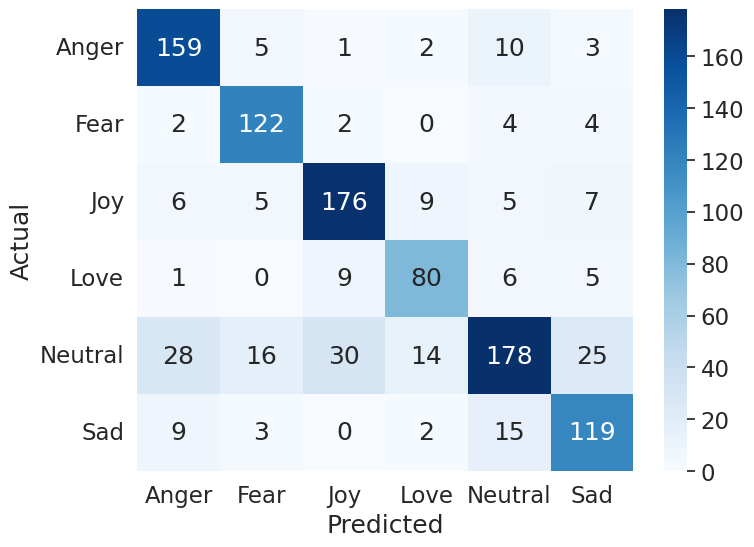

Training finished!


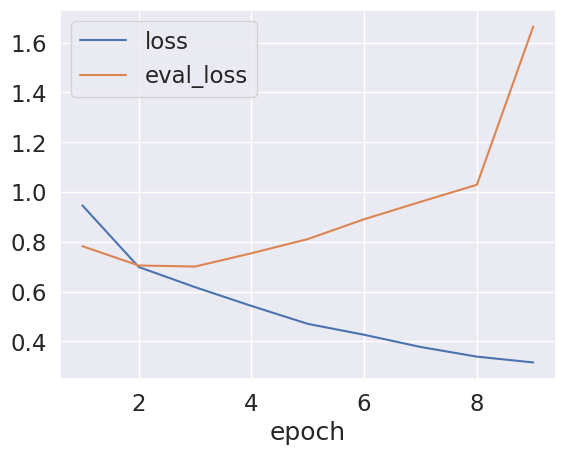

Total time: 7.782311721642812 minutes


In [13]:
#1 IndoBERTweet peft

main(
    model_name = 'indolem/indobertweet-base-uncased',
    output_dir = 'p-emotcls-indobertweet-base',
    best_params = 'best_params/p-indobertweet.json'
)

{'num_train_epochs': 9, 'learning_rate': 0.0001, 'per_device_train_batch_size': 8, 'per_device_eval_batch_size': 8, 'weight_decay': 0.08613430704477265}


config.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/2.24G [00:00<?, ?B/s]

Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at FacebookAI/xlm-roberta-large and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

...

Map:   0%|          | 0/1062 [00:00<?, ? examples/s]

Map:   0%|          | 0/1062 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,1.401600,0.936239,0.691149,0.695671,0.746841,0.698108
2,0.838900,0.817898,0.728814,0.730032,0.770845,0.736302
3,0.749900,0.690784,0.769303,0.766643,0.791892,0.775421
4,0.682000,0.727713,0.757062,0.754564,0.788487,0.764705
5,0.642400,0.723804,0.763653,0.760147,0.791244,0.770721
6,0.591500,0.774961,0.757062,0.754444,0.792853,0.762689
7,0.572700,0.716282,0.769303,0.767264,0.793131,0.776601
8,0.538100,0.752433,0.766478,0.764111,0.797234,0.774419
9,0.518900,0.727628,0.771186,0.766978,0.796771,0.777450


Classification Report:
              precision    recall  f1-score   support

       Anger     0.7048    0.8409    0.7668       176
        Fear     0.7273    0.8707    0.7926       147
         Joy     0.7037    0.7514    0.7268       177
        Love     0.5740    0.8435    0.6831       115
     Neutral     0.8154    0.3557    0.4953       298
         Sad     0.6489    0.8188    0.7240       149

    accuracy                         0.6911      1062
   macro avg     0.6957    0.7468    0.6981      1062
weighted avg     0.7167    0.6911    0.6725      1062

Classification Report:
              precision    recall  f1-score   support

       Anger     0.7004    0.9034    0.7891       176
        Fear     0.8025    0.8571    0.8289       147
         Joy     0.7622    0.7062    0.7331       177
        Love     0.5975    0.8261    0.6934       115
     Neutral     0.8103    0.4732    0.5975       298
         Sad     0.7072    0.8591    0.7758       149

    accuracy                   

Classification Report:
              precision    recall  f1-score   support

       Anger     0.7778    0.8556    0.8148       180
        Fear     0.7083    0.8881    0.7881       134
         Joy     0.7703    0.8221    0.7953       208
        Love     0.7429    0.7723    0.7573       101
     Neutral     0.8122    0.5945    0.6865       291
         Sad     0.7436    0.7838    0.7632       148

    accuracy                         0.7637      1062
   macro avg     0.7592    0.7860    0.7675      1062
weighted avg     0.7689    0.7637    0.7598      1062

{'eval_loss': 0.6769706606864929, 'eval_accuracy': 0.763653483992467, 'eval_precision': 0.7591724734330368, 'eval_recall': 0.7860488952305152, 'eval_f1': 0.7675317511442716, 'eval_runtime': 6.8544, 'eval_samples_per_second': 154.936, 'eval_steps_per_second': 19.404, 'epoch': 9.0}
Classification Report:
              precision    recall  f1-score   support

       Anger     0.7778    0.8556    0.8148       180
        Fear     0.70

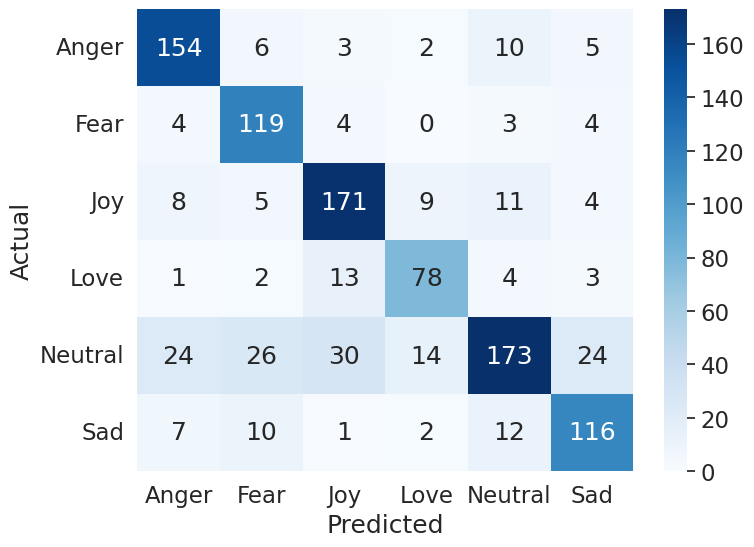

Training finished!


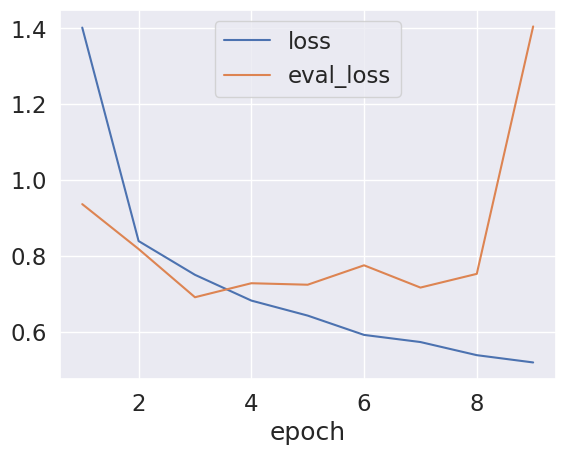

Total time: 19.467379780610404 minutes


In [14]:
#2 FacebookAI/xlm-roberta-large peft

main(
    model_name = 'FacebookAI/xlm-roberta-large',
    output_dir = 'p-emotcls-xlm-r-large',
    best_params = 'best_params/p-xlm-r-large.json'
)

{'num_train_epochs': 7, 'learning_rate': 0.0003, 'per_device_train_batch_size': 32, 'per_device_eval_batch_size': 16, 'weight_decay': 0.044476038650759046}


config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.12G [00:00<?, ?B/s]

Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at FacebookAI/xlm-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

...

Map:   0%|          | 0/1062 [00:00<?, ? examples/s]

Map:   0%|          | 0/1062 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,1.257700,0.889223,0.698682,0.701887,0.745266,0.704761
2,0.903800,0.838465,0.731638,0.732665,0.773098,0.738498
3,0.813300,0.776252,0.734463,0.732948,0.771619,0.743764
4,0.736700,0.755856,0.737288,0.736605,0.770587,0.743898
5,0.699000,0.746946,0.744821,0.741739,0.778930,0.752553
6,0.666000,0.753833,0.734463,0.730980,0.767669,0.741701
7,0.635100,0.766412,0.740113,0.736594,0.772441,0.747682


Classification Report:
              precision    recall  f1-score   support

       Anger     0.7204    0.7614    0.7403       176
        Fear     0.7000    0.9048    0.7893       147
         Joy     0.7378    0.6836    0.7097       177
        Love     0.5455    0.8870    0.6755       115
     Neutral     0.8293    0.4564    0.5887       298
         Sad     0.6784    0.7785    0.7250       149

    accuracy                         0.6987      1062
   macro avg     0.7019    0.7453    0.7048      1062
weighted avg     0.7262    0.6987    0.6903      1062

Classification Report:
              precision    recall  f1-score   support

       Anger     0.6986    0.8693    0.7747       176
        Fear     0.7074    0.9048    0.7940       147
         Joy     0.7987    0.6949    0.7432       177
        Love     0.6556    0.8609    0.7444       115
     Neutral     0.8362    0.4966    0.6232       298
         Sad     0.6994    0.8121    0.7516       149

    accuracy                   

Classification Report:
              precision    recall  f1-score   support

       Anger     0.7833    0.7833    0.7833       180
        Fear     0.6685    0.8881    0.7628       134
         Joy     0.8325    0.7644    0.7970       208
        Love     0.6618    0.8911    0.7595       101
     Neutral     0.7729    0.5498    0.6426       291
         Sad     0.6765    0.7770    0.7233       148

    accuracy                         0.7382      1062
   macro avg     0.7326    0.7756    0.7447      1062
weighted avg     0.7492    0.7382    0.7342      1062

{'eval_loss': 0.7289813756942749, 'eval_accuracy': 0.7382297551789078, 'eval_precision': 0.7325859243635585, 'eval_recall': 0.7756267377301707, 'eval_f1': 0.7447467866031666, 'eval_runtime': 2.1239, 'eval_samples_per_second': 500.012, 'eval_steps_per_second': 31.545, 'epoch': 7.0}
Classification Report:
              precision    recall  f1-score   support

       Anger     0.7833    0.7833    0.7833       180
        Fear     0.6

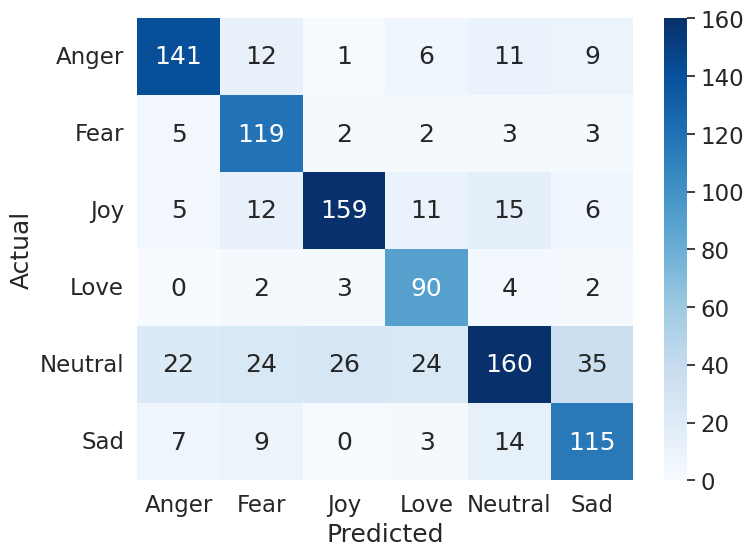

Training finished!


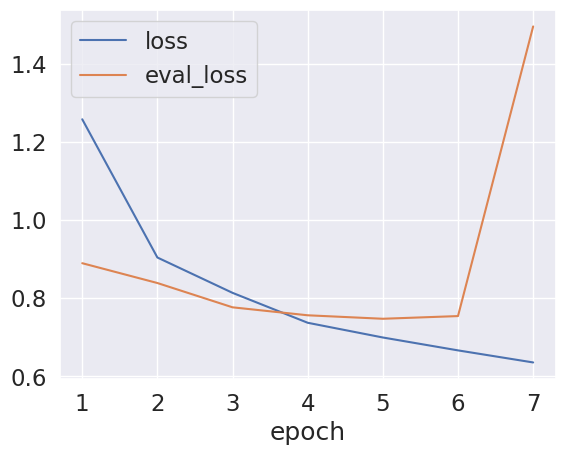

Total time: 4.192773858706157 minutes


In [15]:
#3 FacebookAI/xlm-roberta-base peft

main(
    model_name = 'FacebookAI/xlm-roberta-base',
    output_dir = 'p-emotcls-xlm-r-base',
    best_params = 'best_params/p-xlm-r-base.json'
)

{'num_train_epochs': 6, 'learning_rate': 0.0003, 'per_device_train_batch_size': 8, 'per_device_eval_batch_size': 64, 'weight_decay': 0.06938011248908971}


config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/714M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google-bert/bert-base-multilingual-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

...

Map:   0%|          | 0/1062 [00:00<?, ? examples/s]

Map:   0%|          | 0/1062 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,1.460600,1.077607,0.630885,0.638042,0.670567,0.641632
2,1.028600,0.964723,0.677024,0.680366,0.713635,0.686146
3,0.892300,0.926236,0.693974,0.694923,0.734503,0.703277
4,0.790300,0.899159,0.710923,0.709674,0.742900,0.720309
5,0.724100,0.901509,0.721281,0.720725,0.753608,0.731722
6,0.664900,0.915138,0.720339,0.719115,0.755819,0.730492


Classification Report:
              precision    recall  f1-score   support

       Anger     0.4952    0.5909    0.5389       176
        Fear     0.6944    0.6803    0.6873       147
         Joy     0.6860    0.6667    0.6762       177
        Love     0.5532    0.9043    0.6865       115
     Neutral     0.7158    0.4564    0.5574       298
         Sad     0.6835    0.7248    0.7036       149

    accuracy                         0.6309      1062
   macro avg     0.6380    0.6706    0.6416      1062
weighted avg     0.6492    0.6309    0.6266      1062

Classification Report:
              precision    recall  f1-score   support

       Anger     0.6036    0.7614    0.6734       176
        Fear     0.7303    0.7551    0.7425       147
         Joy     0.7391    0.6723    0.7041       177
        Love     0.5976    0.8783    0.7113       115
     Neutral     0.7449    0.4899    0.5911       298
         Sad     0.6667    0.7248    0.6945       149

    accuracy                   

Classification Report:
              precision    recall  f1-score   support

       Anger     0.7742    0.6667    0.7164       180
        Fear     0.6575    0.8881    0.7556       134
         Joy     0.8360    0.7596    0.7960       208
        Love     0.5860    0.9109    0.7132       101
     Neutral     0.6886    0.5395    0.6050       291
         Sad     0.6776    0.6959    0.6867       148

    accuracy                         0.7053      1062
   macro avg     0.7033    0.7434    0.7121      1062
weighted avg     0.7168    0.7053    0.7020      1062

{'eval_loss': 0.9337918758392334, 'eval_accuracy': 0.7052730696798494, 'eval_precision': 0.7033077132039632, 'eval_recall': 0.7434496146955146, 'eval_f1': 0.7121329724091238, 'eval_runtime': 1.9434, 'eval_samples_per_second': 546.475, 'eval_steps_per_second': 8.748, 'epoch': 6.0}
Classification Report:
              precision    recall  f1-score   support

       Anger     0.7742    0.6667    0.7164       180
        Fear     0.65

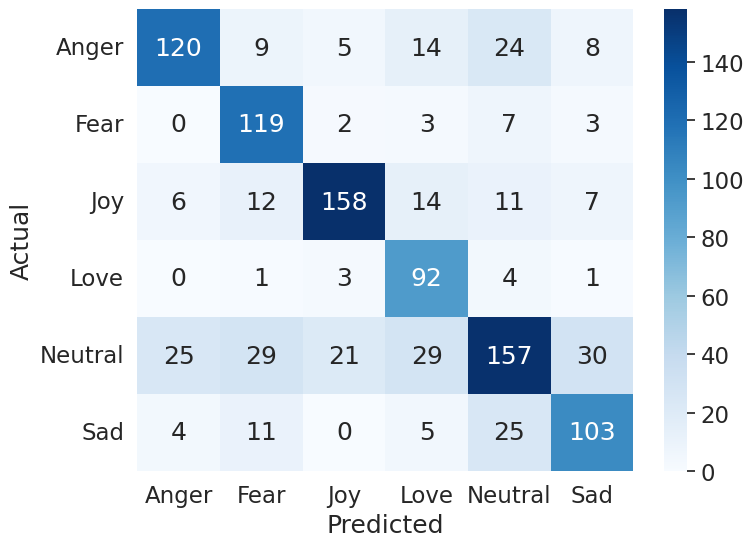

Training finished!


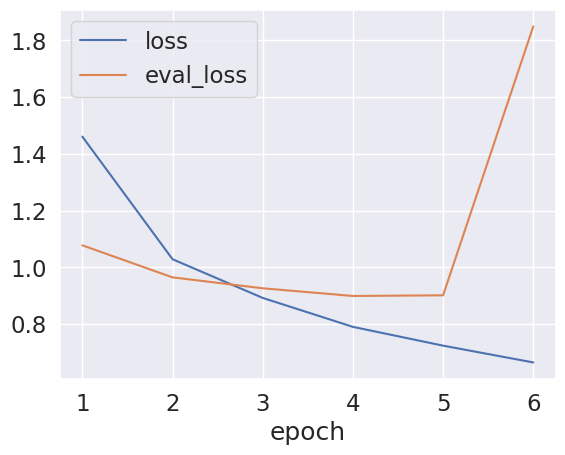

Total time: 5.454877956708272 minutes


In [16]:
#4 google-bert/bert-base-multilingual-cased peft

main(
    model_name = 'google-bert/bert-base-multilingual-cased',
    output_dir = 'p-emotcls-bert-base',
    best_params = 'best_params/p-mbert.json'
)

In [17]:
%cd content/

[Errno 2] No such file or directory: 'content/'
/content/fine_tuning


In [18]:
!zip -r fine_tuning.zip /content/fine_tuning/

  adding: content/fine_tuning/ (stored 0%)
  adding: content/fine_tuning/requirements.txt (deflated 26%)
  adding: content/fine_tuning/dataset/ (stored 0%)
  adding: content/fine_tuning/dataset/val.csv (deflated 57%)
  adding: content/fine_tuning/dataset/test.csv (deflated 57%)
  adding: content/fine_tuning/dataset/get_data_info.ipynb (deflated 49%)
  adding: content/fine_tuning/dataset/train.csv (deflated 58%)
  adding: content/fine_tuning/dataset/train_augmented.csv (deflated 60%)
  adding: content/fine_tuning/dataset/all_data.csv (deflated 60%)
  adding: content/fine_tuning/dataset/.ipynb_checkpoints/ (stored 0%)
  adding: content/fine_tuning/dataset/.ipynb_checkpoints/get_data_info-checkpoint.ipynb (deflated 23%)
  adding: content/fine_tuning/wandb/ (stored 0%)
  adding: content/fine_tuning/wandb/run-20261013_162132-mg8vm4wo/ (stored 0%)
  adding: content/fine_tuning/wandb/run-20261013_162132-mg8vm4wo/tmp/ (stored 0%)
  adding: content/fine_tuning/wandb/run-20261013_162132-mg8vm4wo

In [19]:
from google.colab import files
files.download('fine_tuning.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>